# Author

Vasileios Kochliaridis

# Description

Timeseries Classification Tutorial

# Introduction - Epileptic Seizure

Epileptic seizure is a temporal, abnormal, excessive electrical activity in the brain that causes sudden changes in movement, behavior, feelings, or awareness. Epilepsy is diagnosed when a person has had at least two unprovoked seizures (seizures without a clear, immediate cause) more than 24 hours apart. It can be broken down into:

* **Focal Seizures (Partial Seizures)**: These start in one specific part of the brain. They can be focal aware (the person remains conscious and awake) or focal impaired awareness (the person experiences confusion or a change/loss of consciousness).
* **Generalized Seizures**: These involve networks on both sides of the brain simultaneously right from the start, usually causing an immediate loss of consciousness.

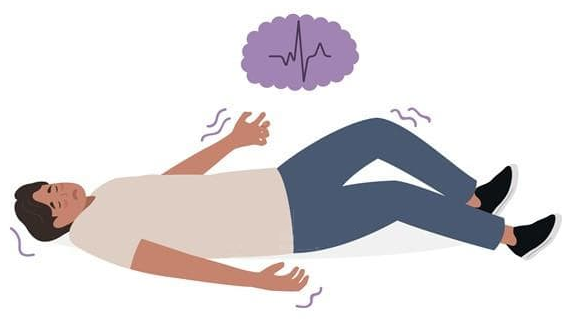

# Responsive Neurostimulation (RNS) Device

RNS is a surgically implanted device that treats seizures. It delivers tiny amounts of electricity to the brain during periods of seizure activity. The RNS System monitors and detects brain waves in the part of the brain where seizures start. When it notices abnormal electrical activity, it responds very quickly by stimulating that area of the brain with a series of electrical pulses. This electrical energy, over time, decreases the brain's ability to generate seizures.

## Limitations

1. Low Computional Capability.
2. Low Storage Capability.

![](https://my.clevelandclinic.org/-/scassets/images/org/health/articles/responsive-neurostimulation)



# EEG (Electroencephalogram)

EEG is a non-invasive method to record the electrical activity of the brain. EEG is widely used both as a clinical diagnostic tool, particularly in epilepsy, and as a research tool in neuroscience. During an EEG, several electrodes are placed along the scalp (commonly called "scalp EEG") using the International 10-20 system.

![](https://www.brainaccess.ai/wp-content/uploads/2022/03/MAXI-layout.jpg)

![](https://bioserenity.ai/wp-content/uploads/2026/06/EEG-Image.jpg)

# Mndeley Data - Epileptic EEG Dataset

This dataset includes the EEG of 6 epileptic patients recorded at the Epilepsy monitoring unit of the American university of Beirut Medical Center between January 2014 and July 2015. The data represents measurements from 21 scalp electrodes, following the 10-20 electrode system, sampled at 500 Hz . All channels have been bandpass filtered between 1/1.6 Hz and 70Hz while filtering out the 50Hz (electrical utility frequency).  Some channels have been omitted from specific recordings due to artifact constraints. The dataset can be found here: https://data.mendeley.com/datasets/5pc2j46cbc/1

## Dataset Description

| Property | Value |
| - | - |
| Patients | 6 |
| EEG electrodes | 21 originally (19 retained) |
| Sampling frequency | 500 Hz |
| Electrode system | International 10-20 |
| Signal format | Raw EEG recordings |
| Classification | 4 classes |
| Recording location | American University of Beirut Medical Center |

## Labels Description

| Label	| Class	| Description |
| - | - | - |
| 0	| Normal EEG | Non-seizure EEG activity |
| 1	| Complex Partial Seizures (CPS) | Seizures involving impaired awareness, generally originating within a focal brain network |
| 2	| Electrographic Seizures | Seizure activity identifiable in EEG recordings, potentially without obvious clinical manifestations |
| 3	| Video-Detected Seizures | Events identified through video monitoring without clearly visible corresponding changes in the scalp EEG |

# Artifacts of EEG

One of the main challenges in working with electroencephalographic (EEG) data is ensuring that the recorded signals are clean and exhibit a high signal-to-noise ratio (SNR). Because EEG amplitudes are typically in the microvolt range, they are highly susceptible to various sources of contamination, commonly referred to as artifacts. These unwanted signals can obscure the underlying neural activity and compromise the quality of the data, making artifact detection and removal essential for accurate analysis and reliable applications.

![](https://cdnintech.com/media/chapter/54606/1512345123/media/F2.png)

# Bandpass Filter

An EEG bandpass filter combines a high-pass filter and a low-pass filter to let specific brain frequency ranges pass through while blocking unwanted noise and artifacts. The Bandpass Range is typically set between 1 Hz and 70 Hz (or 0.5 Hz to 40/50 Hz depending on the analysis goal) to isolate core cortical waveforms.

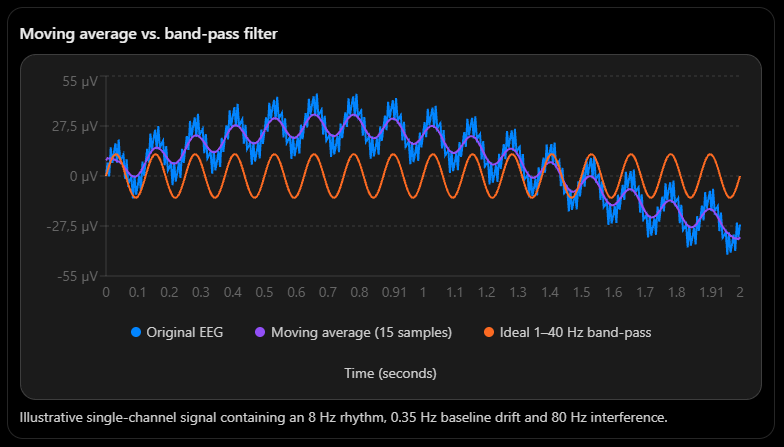

# Import Libraries

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.signal import welch
from scipy.stats import kurtosis, skew
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from tqdm import tqdm

# Download EEG Data

Using `wget` linux command to download EEG data files (as numpy arrays .npy) to Google Colab.

In [1]:
!wget https://data.mendeley.com/public-files/datasets/5pc2j46cbc/files/93b81166-0e48-4dc0-ac20-b7167f7606c5/file_downloaded -O x_test.npy
!wget https://data.mendeley.com/public-files/datasets/5pc2j46cbc/files/169dca1c-4992-43d3-9c94-030de59c2524/file_downloaded -O x_train.npy
!wget https://data.mendeley.com/public-files/datasets/5pc2j46cbc/files/adf1c2fd-81ef-4f87-86cc-56d75bba8c31/file_downloaded -O y_test.npy
!wget https://data.mendeley.com/public-files/datasets/5pc2j46cbc/files/62accb90-a1b2-4b50-bde5-fbe6096f165f/file_downloaded -O y_train.npy

--2026-11-05 16:19:37--  https://data.mendeley.com/public-files/datasets/5pc2j46cbc/files/93b81166-0e48-4dc0-ac20-b7167f7606c5/file_downloaded
Resolving data.mendeley.com (data.mendeley.com)... 162.159.130.86, 162.159.133.86
Connecting to data.mendeley.com (data.mendeley.com)|162.159.130.86|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com/9cf22fc5-0e60-4042-b880-0467c7d55a01 [following]
--2026-11-05 16:19:38--  https://prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com/9cf22fc5-0e60-4042-b880-0467c7d55a01
Resolving prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com (prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com)... 3.5.66.8, 52.92.16.242, 3.5.72.99, ...
Connecting to prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com (prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com)|3.5.66.8|:443... connect

# Load Numpy Arrays

In [3]:
x_train = np.load('x_train.npy')
x_test = np.load('x_test.npy')
y_train = np.load('y_train.npy')
y_test = np.load('y_test.npy')

x_train.shape, x_test.shape, y_train.shape, y_test.shape

((7011, 19, 500), (779, 19, 500), (7011,), (779,))

# Dataset Inspection

## Class Inspection

Classes are imbalanced, but stratified sampling has been used for train-test split.

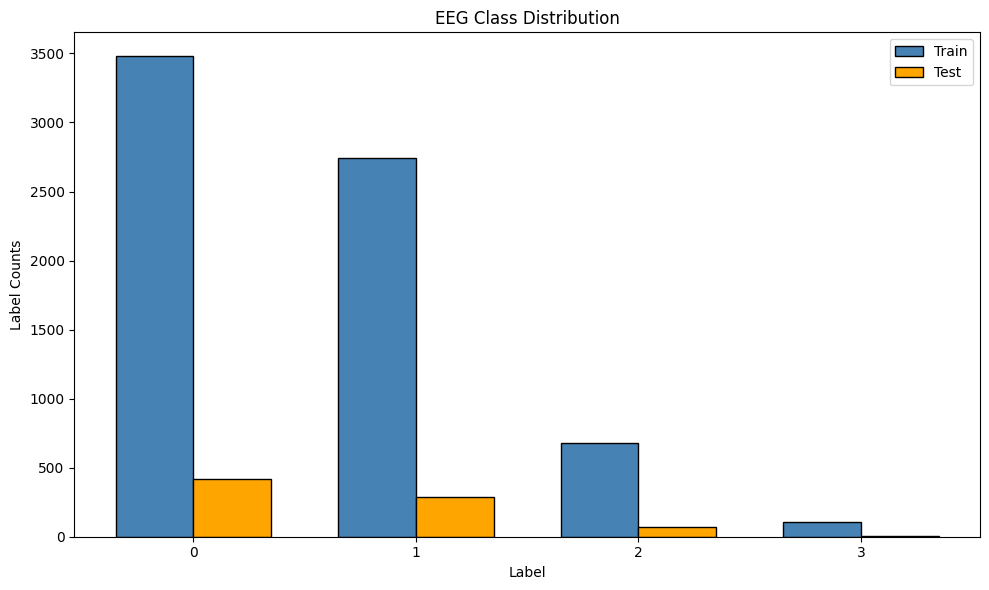

In [4]:
y_train_counts = pd.Series(y_train).value_counts().sort_index()
y_test_counts = pd.Series(y_test).value_counts().sort_index()

x = np.arange(y_train_counts.shape[0])
width = 0.35
plt.figure(figsize=(10, 6))
plt.bar(x - width/2, y_train_counts, width, label='Train', color='steelblue', edgecolor='black')
plt.bar(x + width/2, y_test_counts, width, label='Test', color='orange', edgecolor='black')

plt.title('EEG Class Distribution')
plt.xlabel('Label')
plt.ylabel('Label Counts')
plt.xticks(x, y_train_counts.index)
plt.legend()
plt.tight_layout()
plt.show()

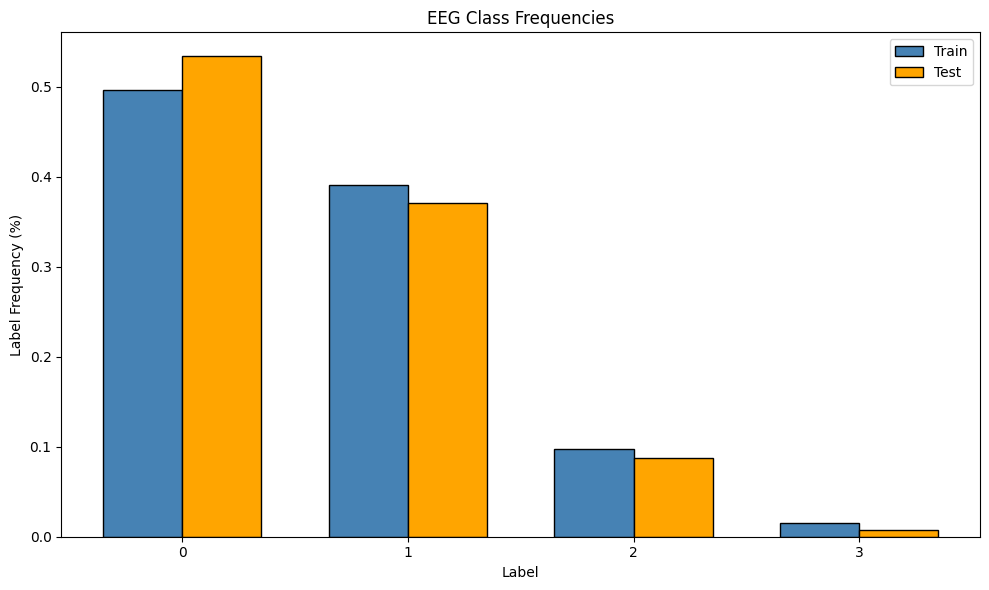

In [5]:
y_train_counts = pd.Series(y_train).value_counts(normalize=True).sort_index()
y_test_counts = pd.Series(y_test).value_counts(normalize=True).sort_index()

plt.figure(figsize=(10, 6))
plt.bar(x - width/2, y_train_counts, width, label='Train', color='steelblue', edgecolor='black')
plt.bar(x + width/2, y_test_counts, width, label='Test', color='orange', edgecolor='black')

plt.title('EEG Class Frequencies')
plt.xlabel('Label')
plt.ylabel('Label Frequency (%)')
plt.xticks(x, y_train_counts.index)
plt.legend()
plt.tight_layout()
plt.show()

## Signal Inspection

Seizure $\rightarrow$ intense and abnormal brain activity.

In [6]:
labels = {0: 'Normal Patient', 1: 'Complex Partial Seizure', 2: 'Electrographic Seizure', 3: 'Video-Detected Seizure'}
fs = 500
n_channels = x_train.shape[1]

for label, description in labels.items():
    random_idx = np.where(y_train == label)[0][0]
    eeg = x_train[random_idx]
    time = np.arange(eeg.shape[1])/fs

    fig = make_subplots(rows=n_channels, cols=1, shared_xaxes=True, vertical_spacing=0.005)
    for ch in range(n_channels):
        fig.add_trace(
            go.Scatter(
                x=time,
                y=eeg[ch],
                mode="lines",
                line=dict(color="royalblue", width=1),
                name=f"Channel {ch + 1}",
                showlegend=False
            ),
            row=ch + 1,
            col=1
        )
        fig.update_xaxes(
            showline=True,
            mirror=True,
            linecolor="black",
            linewidth=1,
            showgrid=False,
            zeroline=False,
            row=ch + 1,
            col=1
        )
        fig.update_yaxes(
            title_text=f"Ch {ch + 1}",
            showticklabels=False,
            showline=True,
            mirror=True,
            linecolor="black",
            linewidth=1,
            showgrid=False,
            zeroline=False,
            row=ch + 1,
            col=1
        )
    fig.update_xaxes(title_text="Time (seconds)", row=19, col=1)
    fig.update_layout(
        title=f"Randomly Selected EEG for {description}",
        height=1600,
        width=1100,
        plot_bgcolor="white",
        paper_bgcolor="white",
        font=dict(size=12)
    )
    fig.show()

In [7]:
colors = {0: 'green', 1: 'orange', 2: 'red', 3: 'purple'}

segments = []
for label in labels:
    idx = np.where(y_train == label)[0][0]
    segments.append(x_train[idx])

eeg = np.concatenate(segments, axis=1)
fig = make_subplots(rows=19, cols=1, shared_xaxes=True, vertical_spacing=0.008)
segment_length = segments[0].shape[1]
for ch in range(19):
    for i, label in enumerate(labels):
        start = i * segment_length
        end = start + segment_length
        time = np.arange(start, end) / fs
        fig.add_trace(
            go.Scatter(
                x=time,
                y=eeg[ch, start:end],
                mode="lines",
                line=dict(color=colors[label], width=1),
                name=labels[label],
                legendgroup=str(label),
                showlegend=(ch == 0)
            ),
            row=ch + 1,
            col=1
        )
    fig.update_xaxes(
        showline=True,
        mirror=True,
        linecolor="black",
        linewidth=1,
        showgrid=False,
        zeroline=False,
        row=ch + 1,
        col=1
    )
    fig.update_yaxes(
        title_text=f"Ch {ch + 1}",
        showticklabels=False,
        showline=True,
        mirror=True,
        linecolor="black",
        linewidth=1,
        showgrid=False,
        zeroline=False,
        row=ch + 1,
        col=1
    )
for t in [1, 2, 3]:
    fig.add_vline(
        x=t,
        line_dash="dash",
        line_color="gray",
        line_width=1
    )
fig.update_xaxes(title_text="Time (seconds)", row=19, col=1)
fig.update_layout(
    title="EEG Signals: Normal vs Seizure Classes",
    height=1600,
    width=1200,
    plot_bgcolor="white",
    paper_bgcolor="white",
    font=dict(size=12),
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="center",
        x=0.5
    )
)
fig.show()

# Curse of Dimensionality

Each EEG Signal lasts 1s with 2ms sampling rate, 500 samples extracted. Each sample includes 19 channels. Number of inputs: $R^{19 \times 500} \rightarrow R^{9500}$ as a flattened vector. However, several issues can arise here:

1. **High Bias** - Algorithms such as Logistic Regression, KNN, GNB struggle with many dimensions.
2. **High Computational Demands** - Neural Nets & KNN impossible to work inside the chip.

![](https://media.licdn.com/dms/image/v2/D4D12AQF0V9o53Sek3w/article-cover_image-shrink_720_1280/B4DZhesQ9VGsAI-/0/1753935342419?e=2147483647&v=beta&t=L6Ih7TRjOVIzvj3J_vngmRFrLcmPe_6bZlYV8b713Jg)

# Feature Extraction

Consider a channel containing: $X=[x_1,x_2,\ldots,x_{N}]$ we can extract the following features:

* **Mean**: $\mu = \frac{1}{N}\sum_{i=1}^{N} x_{i}$
* **Standard Deviaiton**: $\sigma = \sqrt{\frac{1}{N-1}\sum_{i=1}^{N} (x_{i} - \mu)^{2}}$
* **Peak-to-Peak Amplitude**: $V_{p-p}=\max{x_{i}} - \min{x_{i}}$
* **Normalized Line Length**: $LL=\frac{1}{N-1}\sum_{i=1}^{N-1} |x_{i+1}-x_{i}|$
* **Zero Crossing Rate**: How many times signal crosses 0
* **Skewness**: Asymmetry of the amplitude distribution.
* **Kurtosis**: Sensitive to sharp peaks and outliers
* **Power Band**: Checks how many times the signal oscillates within a specified frequency: $P_{band} = \int_{f_{low}}^{f_{high}}PSD(f)df$ Common power bands:
    * Delta: 0.5-4 Hz
    * Theta: 4-8 Hz
    * Alpha: 8-13 Hz
    * Beta: 13-30 Hz
    * Gamma: 30-80+ Hz
* **Spectral Entropy**:	Distribution of signal power across frequencies.

In [8]:
fs = 500
bands = {"Delta": (0.5, 4), "Theta": (4, 8), "Alpha": (8, 13), "Beta": (13, 30), "Gamma": (30, 70)}

extracted = []
for X in [x_train, x_test]:
    # Time-domain features
    mean = np.mean(X, axis=-1)
    std = np.std(X, axis=-1, ddof=1)
    peak_to_peak = np.ptp(X, axis=-1)
    line_length = np.mean(np.abs(np.diff(X, axis=-1)), axis=-1)
    zero_crossing = np.mean(np.signbit(X[..., 1:]) != np.signbit(X[..., :-1]), axis=-1)
    skewness = np.nan_to_num(skew(X, axis=-1, bias=False))
    kurt = np.nan_to_num(kurtosis(X, axis=-1, fisher=True, bias=False))

    features = [
        mean,
        std,
        peak_to_peak,
        line_length,
        zero_crossing,
        skewness,
        kurt
    ]

    # Frequency-domain features
    freqs, psd = welch(X, fs=fs, nperseg=X.shape[-1], axis=-1)
    df = freqs[1] - freqs[0]

    for low, high in bands.values():
        mask = (freqs >= low) & (freqs < high)
        band_power = np.sum(psd[..., mask], axis=-1) * df
        features.append(band_power)

    # Spectral entropy
    mask = (freqs >= 1) & (freqs < 70)
    spectrum = psd[..., mask]

    p = spectrum / np.maximum(np.sum(spectrum, axis=-1, keepdims=True), 1e-12)
    spectral_entropy = -np.sum(p * np.log(p + 1e-12), axis=-1)/np.log(spectrum.shape[-1])
    features.append(spectral_entropy)

    # Concatenate features across channels
    extracted.append(np.concatenate(features, axis=1))

x_train_feats, x_test_feats = extracted

x_train_feats.shape, x_test_feats.shape

((7011, 247), (779, 247))

# Gaussian Naive-Bayes Training

## Evaluating Performance with 5-Fold Cross-Validation

In [9]:
seed = 0
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

results = []
for fold, (train_idx, val_idx) in tqdm(enumerate(cv.split(x_train_feats, y_train), 1), desc='Fold'):
    # Extracting fold train-test input-target data.
    X_tr, X_val = x_train_feats[train_idx], x_train_feats[val_idx]
    y_tr, y_val = y_train[train_idx], y_train[val_idx]

    # Train-Eval.
    model = GaussianNB()
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)
    results.append({
        'Fold': fold,
        'Accuracy': accuracy_score(y_val, y_pred),
        'Precision': precision_score(y_val, y_pred, average='macro', zero_division=0),
        'Recall': recall_score(y_val, y_pred, average='macro', zero_division=0),
        'F1': f1_score(y_val, y_pred, average='macro', zero_division=0),
        'Balanced Accuracy': balanced_accuracy_score(y_val, y_pred),
        'ROC-AUC': roc_auc_score(y_val, y_prob, multi_class='ovr', average='macro', labels=model.classes_)
    })

cv_results = pd.DataFrame(results).set_index("Fold")
cv_results.loc['Average'] = cv_results.mean()
cv_results = cv_results.round(4)
cv_results

Fold: 5it [00:00, 15.24it/s]


,Accuracy,Precision,Recall,F1,Balanced Accuracy,ROC-AUC
Fold,,,,,,
1,0.7534,0.6469,0.8206,0.6768,0.8206,0.8975
2,0.8081,0.6947,0.8477,0.7280,0.8477,0.9326
3,0.7632,0.6913,0.8060,0.7117,0.8060,0.9107
4,0.7846,0.7143,0.8540,0.7476,0.8540,0.9306
5,0.7696,0.6666,0.8149,0.6935,0.8149,0.9221
Average,0.7758,0.6828,0.8286,0.7115,0.8286,0.9187


In [10]:
gnb_acc = [
    round(cv_results['Accuracy'].mean() - cv_results['Accuracy'].std(), 2),
    round(cv_results['Accuracy'].mean() + cv_results['Accuracy'].std(), 2)
]
gnb_acc

[np.float64(0.76), np.float64(0.79)]

## Train-Test GNB

In [11]:
model = GaussianNB()
model.fit(x_train_feats, y_train)
y_pred = model.predict(x_test_feats)
y_prob = model.predict_proba(x_test_feats)
test_results = pd.DataFrame([{
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, average='macro', zero_division=0),
    'Recall': recall_score(y_test, y_pred, average='macro', zero_division=0),
    'F1': f1_score(y_test, y_pred, average='macro', zero_division=0),
    'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_prob, multi_class='ovr', average='macro', labels=model.classes_)
}], index=['Test'])
test_results = test_results.round(4)
test_results

,Accuracy,Precision,Recall,F1,Balanced Accuracy,ROC-AUC
Test,0.7702,0.6234,0.8549,0.649,0.8549,0.9192
